# Nguồn cung: Người bán

| # | Câu hỏi |
|---|---|
| 1 | Người bán đang ở quy mô nào? | 
| 2 | Người bán phân tầng thế nào? Nhóm nào nuôi sàn? | 
| 3 | Doanh thu đến từ người bán lâu năm hay người bán mới? Người bán có ở lại không? | 
| 4 | Ngành nào phụ thuộc vào vài người bán? Bán nhiều ngành có đi kèm doanh thu cao hơn? | 
| 5 | Bao nhiêu doanh thu đang nằm trong tay người bán phục vụ kém? | 
| 6 | Tóm lại, insight quan trọng nhất là gì? | 

### Quy ước
- **Tập đơn:** mọi biểu đồ tính trên **dòng sản phẩm thuộc đơn hợp lệ** (đơn có sản phẩm, trạng thái khác `canceled` / `unavailable`), trừ khi tiêu đề ghi khác.
  Riêng §5: điểm review tính trên đơn có review, % giao trễ tính trên đơn đã giao.
- **Doanh thu (GMV)** = `price + freight_value` (BRL).
- **Người bán** = `seller_key`. **Sản phẩm (SKU)** = `product_id`. **Số sản phẩm đã bán** = số dòng trong `fact_order_items` (1 dòng = 1 sản phẩm; khác với số SKU).
- **Ngành hàng** = `product_category_name_english` (sản phẩm không có ngành gom vào `unknown`).
- **Kỳ so sánh (YoY):** kỳ này so với cùng kỳ năm trước, suy ra từ dữ liệu trong `common.connect()` (giống `executive_overview`; hiện là 01–08/2018 so với 01–08/2017).
  Biểu đồ theo tháng dùng cửa sổ xu hướng chung (hiện là **01/2017 → 08/2018**).
- Mọi ngưỡng (tầng người bán, ngưỡng rủi ro…) được khai báo **một lần** ở cell cấu hình bên dưới.
- Kết nối, kỳ phân tích, bảng màu, hàm trục, KPI, bảng `order_base` / `item_ps` và ngưỡng `MIN_SELLER_ORDERS` lấy từ package `common`.

## 0. Kết nối lakehouse & nạp dữ liệu Silver

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from common import *   # kết nối, kỳ phân tích, bảng màu, hàm trục, KPI, item_ps

con, P = connect(["dim_seller", "dim_product", "dim_category"])
apply_theme()

Kỳ này 01–08/2018 | cùng kỳ 01–08/2017 | xu hướng 01/2017–08/2018 | 98,059 đơn, 96,817 đơn hợp lệ


In [2]:
# ---------- Ngưỡng phân tích (khai báo một lần, dùng cho mọi phần) ----------
SELLER_TIER_EDGES = band_edges(GOLD.SELLER_TIERS)                # GMV toàn kỳ của người bán (BRL)
SELLER_TIER_NAMES = ["Siêu nhỏ", "Nhỏ", "Vừa", "Lớn", "Chiến lược"]
TOP_TIERS = ["Lớn", "Chiến lược"]
CATEGORY_COUNT_EDGES = band_edges(GOLD.CATEGORY_COUNT_BANDS)     # số ngành người bán bán (khoảng đóng bên phải)
CATEGORY_COUNT_LABELS = band_order(GOLD.CATEGORY_COUNT_BANDS)
ACTIVE_FROM_MONTH, ACTIVE_TO_MONTH = GOLD.ACTIVE_FROM_MONTH, GOLD.ACTIVE_TO_MONTH   # "còn bán" = có đơn ở tháng thứ 6–8 sau tháng đầu
REVIEW_EDGES = band_edges(GOLD.SELLER_REVIEW_BANDS)
RISK_REVIEW = 3.8                                                # điểm review dưới mức này = doanh thu rủi ro
GOOD_REVIEW = 4.0                                                # từ mức này trở lên = phục vụ tốt
assert RISK_REVIEW in REVIEW_EDGES and GOOD_REVIEW in REVIEW_EDGES
TOP3_HIGH, TOP3_MEDIUM = 0.40, 0.25                              # tỷ trọng top 3 người bán trong ngành: cao / trung bình

SELLER_TIER_LABELS = [f"{n} ({r})" for n, r in zip(SELLER_TIER_NAMES, band_labels(SELLER_TIER_EDGES, lambda v: f"{v/1e3:g}K"))]
TOP_TIER_LABELS = [l for n, l in zip(SELLER_TIER_NAMES, SELLER_TIER_LABELS) if n in TOP_TIERS]
REVIEW_LABELS = band_labels(REVIEW_EDGES, lambda v: f"{v:.1f}")

### Tạo bảng phân tích
- `item_ps`: **1 dòng / đơn vị sản phẩm trong đơn hợp lệ**: thời gian mua, ngành, SKU, người bán (bang/vùng), khách (bang), giá, phí ship, GMV.
  Tạo bằng `create_item_ps()` của `common/tables.py`, dùng chung với notebook `product` nên hai notebook ra cùng con số.
- `order_q`: chỉ số chất lượng **theo đơn hợp lệ** (điểm review TB, cờ không hài lòng, cờ giao trễ), lấy từ `order_base`.
- `seller_ps` → DataFrame `sellers`: **1 dòng / người bán**, gom mọi thuộc tính dùng ở §2–§5 (quy mô, độ rộng danh mục, cohort, cờ còn bán, chất lượng, hạng GMV)
  để các phần sau chỉ đọc, không thêm cột. Cohort trước cửa sổ xu hướng được gộp theo năm, từ đó trở đi theo quý.

In [3]:
create_item_ps()
con.execute("CREATE OR REPLACE TABLE order_q AS SELECT order_key, review_score, is_negative, is_late FROM order_base WHERE is_valid = 1")
con.execute(f"""
CREATE OR REPLACE TABLE seller_ps AS
WITH base AS (
    SELECT seller_key, arbitrary(seller_id) AS seller_id, arbitrary(seller_state) AS seller_state,
           arbitrary(seller_region) AS seller_region, sum(gmv) AS gmv, count(*) AS units,
           count(DISTINCT order_key) AS orders, count(DISTINCT product_id) AS skus, count(DISTINCT category) AS n_categories,
           count(DISTINCT customer_state) AS n_customer_states, avg(price) AS avg_price, min(purchase_month) AS first_month
    FROM item_ps GROUP BY 1),
quality AS (   -- điểm review / không hài lòng: đơn có review; giao trễ: đơn đã giao
    SELECT so.seller_key, avg(oq.review_score) AS avg_review, avg(oq.is_negative) AS negative_rate, avg(oq.is_late) AS late_rate
    FROM (SELECT DISTINCT seller_key, order_key FROM item_ps) so JOIN order_q oq USING (order_key) GROUP BY 1),
activity AS (  -- có bán trong tháng thứ {ACTIVE_FROM_MONTH}–{ACTIVE_TO_MONTH} sau tháng đầu tiên?
    SELECT b.seller_key,
           max(CAST(m.purchase_month BETWEEN b.first_month + INTERVAL '{ACTIVE_FROM_MONTH}' MONTH
                                         AND b.first_month + INTERVAL '{ACTIVE_TO_MONTH}' MONTH AS INTEGER)) AS active_later
    FROM base b JOIN (SELECT DISTINCT seller_key, purchase_month FROM item_ps) m ON m.seller_key = b.seller_key GROUP BY 1)
SELECT b.*,
       CASE WHEN b.first_month < DATE '{P.m_start}' THEN CAST(year(b.first_month) AS VARCHAR)
            ELSE CAST(year(b.first_month) AS VARCHAR) || '-Q' || CAST(quarter(b.first_month) AS VARCHAR) END AS cohort,
       -- chỉ cohort đã có đủ {ACTIVE_TO_MONTH} tháng quan sát mới được tính tỷ lệ còn bán (tránh lệch do dữ liệu bị cắt ở tháng báo cáo)
       b.first_month + INTERVAL '{ACTIVE_TO_MONTH}' MONTH <= DATE '{P.m_end}' AS retention_observable,
       a.active_later, qa.avg_review, qa.negative_rate, qa.late_rate,
       rank() OVER (ORDER BY b.gmv DESC) AS gmv_rank
FROM base b LEFT JOIN quality qa ON qa.seller_key = b.seller_key LEFT JOIN activity a ON a.seller_key = b.seller_key
""")

sellers = q("SELECT * FROM seller_ps")
sellers["tier"] = pd.cut(sellers.gmv, SELLER_TIER_EDGES, labels=SELLER_TIER_LABELS, right=False)
sellers["category_count_band"] = pd.cut(sellers.n_categories, CATEGORY_COUNT_EDGES, labels=CATEGORY_COUNT_LABELS)
sellers["review_band"] = pd.cut(sellers.avg_review.where(sellers.orders >= MIN_SELLER_ORDERS), REVIEW_EDGES,
                                labels=REVIEW_LABELS, right=False)
TOTAL_GMV = sellers.gmv.sum()

print(q("""SELECT count(*) AS valid_items, count(DISTINCT order_key) AS valid_orders, count(DISTINCT product_id) AS skus,
                  count(DISTINCT seller_key) AS sellers, count(DISTINCT category) AS categories,
                  round(sum(gmv) / 1e6, 2) AS gmv_mil
           FROM item_ps""").to_string(index=False))

 valid_items  valid_orders  skus  sellers  categories  gmv_mil
      110500         96817 32399     3042          74    15.53


## 1. KPI & năng suất người bán theo tháng
*Câu hỏi: "Sàn có bao nhiêu người bán hoạt động, mỗi người bán tạo bao nhiêu doanh thu? Nguồn cung có đang tăng nhanh hơn nhu cầu không?"*

Chỉ số so sánh bằng **% thay đổi**, dùng chung bảng `COMPARE` trong `common/kpi.py`.
GMV toàn sàn không lặp lại ở đây (xem `executive_overview` §1).
- **Người bán hoạt động** trong tháng = người bán có ít nhất 1 sản phẩm trong đơn hợp lệ của tháng đó. **Người bán mới** = người bán có tháng bán đầu tiên là tháng đó.

In [4]:
def seller_kpis(where: str) -> dict:
    k = q(f"""SELECT sum(gmv) AS gmv, count(*) AS units, count(DISTINCT product_id) AS skus,
                     count(DISTINCT seller_key) AS sellers
              FROM item_ps WHERE {where}""").iloc[0].to_dict()
    k["gmv_per_seller"] = k["gmv"] / k["sellers"]
    k["units_per_seller"] = k["units"] / k["sellers"]
    k["skus_per_seller"] = k["skus"] / k["sellers"]
    return k

KPIS = [
    Kpi("gmv", "Doanh thu GMV (BRL)", "{:,.0f}", "pct"),
    Kpi("sellers", "Người bán hoạt động", "{:,.0f}", "pct"),
    Kpi("gmv_per_seller", "GMV / người bán (BRL)", "{:,.0f}", "pct"),
    Kpi("units_per_seller", "Số sản phẩm đã bán / người bán", "{:,.1f}", "pct"),
    Kpi("skus_per_seller", "SKU / người bán", "{:,.1f}", "pct"),
]
kpi_table(KPIS, seller_kpis, P)

,Toàn kỳ,01–08/2017,01–08/2018,Thay đổi YoY
Chỉ số,,,,
Doanh thu GMV (BRL),"15,526,006","3,564,588","8,398,428",+135.6%
Người bán hoạt động,"3,042","1,208","2,344",+94.0%
GMV / người bán (BRL),"5,104","2,951","3,583",+21.4%
Số sản phẩm đã bán / người bán,36.3,21.1,25.5,+20.8%
SKU / người bán,10.7,8.1,8.5,+5.8%


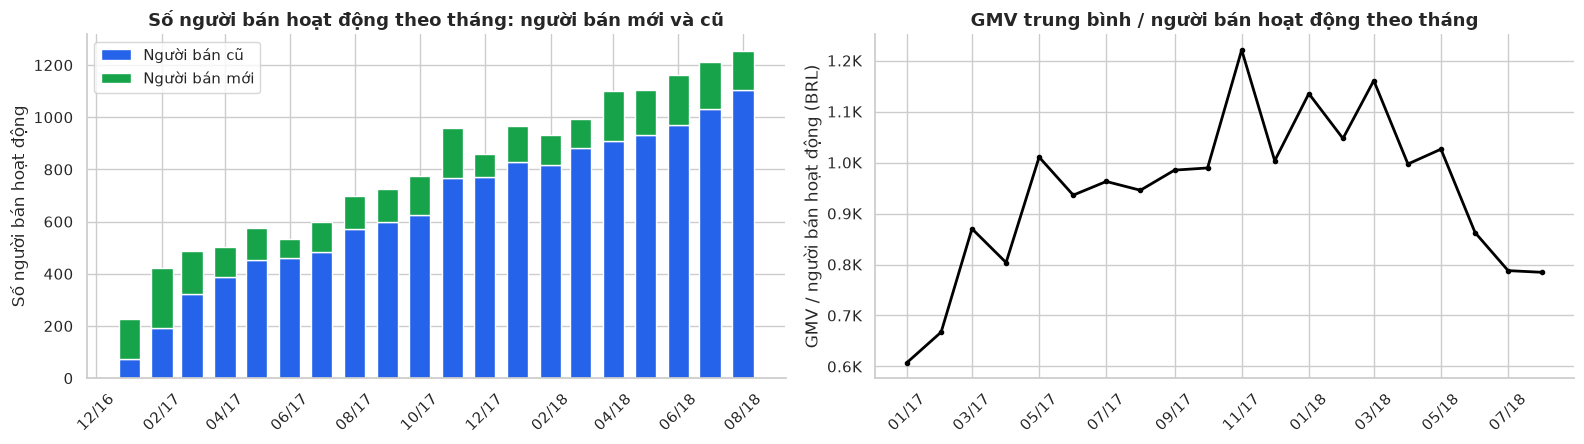

01–08/2017: người bán HĐ TB/tháng 506 | người bán mới TB/tháng 138 | GMV/người bán 851
01–08/2018: người bán HĐ TB/tháng 1,091 | người bán mới TB/tháng 157 | GMV/người bán 975
GMV/người bán: đỉnh 03/2018 1,161 → 08/2018 785 (-32%)
01/2018 → 08/2018: người bán HĐ 968 → 1,255 (+30%) | số đơn 7,162 → 6,335 (-12%)


In [5]:
# Người bán hoạt động (mới / cũ) và GMV trên mỗi người bán hoạt động, theo tháng
monthly_supply = q(f"""WITH seller_first AS (SELECT seller_key, min(purchase_month) AS first_month FROM item_ps GROUP BY 1)
                       SELECT i.purchase_month AS month, count(DISTINCT i.seller_key) AS active_sellers,
                              count(DISTINCT i.seller_key) FILTER (WHERE f.first_month = i.purchase_month) AS new_sellers,
                              count(DISTINCT i.order_key) AS orders, sum(i.gmv) AS gmv
                       FROM item_ps i JOIN seller_first f ON f.seller_key = i.seller_key
                       WHERE {P.in_period} GROUP BY 1 ORDER BY 1""")
monthly_supply["month"] = pd.to_datetime(monthly_supply.month)
monthly_supply["gmv_per_seller"] = monthly_supply.gmv / monthly_supply.active_sellers

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.6))
ax1.bar(monthly_supply.month, monthly_supply.active_sellers - monthly_supply.new_sellers, width=20, color=C_MAIN, label="Người bán cũ")
ax1.bar(monthly_supply.month, monthly_supply.new_sellers, width=20, bottom=monthly_supply.active_sellers - monthly_supply.new_sellers,
        color=C_GOOD, label="Người bán mới")
ax1.set_ylabel("Số người bán hoạt động"); month_axis(ax1); ax1.legend(loc="upper left")
ax1.set_title("Số người bán hoạt động theo tháng: người bán mới và cũ")
ax2.plot(monthly_supply.month, monthly_supply.gmv_per_seller, color="black", marker="o", ms=3, lw=2)
brl_axis(ax2, unit="K"); ax2.set_ylabel("GMV / người bán hoạt động (BRL)"); month_axis(ax2)
ax2.set_title("GMV trung bình / người bán hoạt động theo tháng")
plt.tight_layout(); plt.show()

supply_by_month = monthly_supply.set_index("month")
def months_of(year):   # các tháng 01 → tháng báo cáo của một năm
    idx = supply_by_month.index
    return supply_by_month[(idx.year == year) & (idx.month <= P.last_mon)]
supply_prev, supply_cur = months_of(P.year_prev), months_of(P.year_cur)
for year, period in [(P.year_prev, supply_prev), (P.year_cur, supply_cur)]:
    print(f"{P.label(year)}: người bán HĐ TB/tháng {period.active_sellers.mean():,.0f} | người bán mới TB/tháng {period.new_sellers.mean():,.0f} | "
          f"GMV/người bán {period.gmv_per_seller.mean():,.0f}")
peak_month = supply_cur.gmv_per_seller.idxmax()
first, last = supply_cur.iloc[0], supply_cur.iloc[-1]
print(f"GMV/người bán: đỉnh {peak_month:%m/%Y} {supply_cur.gmv_per_seller[peak_month]:,.0f} → {last.name:%m/%Y} {last.gmv_per_seller:,.0f} "
      f"({last.gmv_per_seller / supply_cur.gmv_per_seller[peak_month] - 1:+.0%})")
print(f"{first.name:%m/%Y} → {last.name:%m/%Y}: người bán HĐ {first.active_sellers:,.0f} → {last.active_sellers:,.0f} ({last.active_sellers / first.active_sellers - 1:+.0%}) | "
      f"số đơn {first.orders:,.0f} → {last.orders:,.0f} ({last.orders / first.orders - 1:+.0%})")

> **🔎 Kết quả chính**
> - Toàn kỳ: **3.053 người bán** có đơn hợp lệ.
> - So 2 kỳ 8 tháng: người bán hoạt động **+94%**, chậm hơn GMV (+140%), nên **GMV / người bán +23,8%** (2.950 → 3.650 BRL).
> - Nhưng **trong 2018 cung đang vượt cầu**: 01 → 08/2018 người bán hoạt động **+31%** (968 → 1.266) trong khi số đơn **−11%** (7.187 → 6.421);
>   **GMV / người bán hoạt động giảm 32%**, từ đỉnh 1.161 BRL (03/2018) xuống 787 BRL (08/2018). Mỗi tháng vẫn có thêm ~140–160 người bán mới.
> - Nếu doanh số mỗi người bán tiếp tục giảm, sàn có nguy cơ **mất người bán**: cần ưu tiên **kéo cầu** hơn là tuyển người bán đại trà.

## 2. Phân tầng người bán theo doanh thu
*Câu hỏi: "Người bán phân hóa thế nào? Nhóm nào thực sự nuôi sàn?"*

Chia người bán thành **5 tầng theo tổng GMV toàn kỳ**
và so sánh quy mô, độ rộng danh mục, phạm vi thị trường của từng tầng.

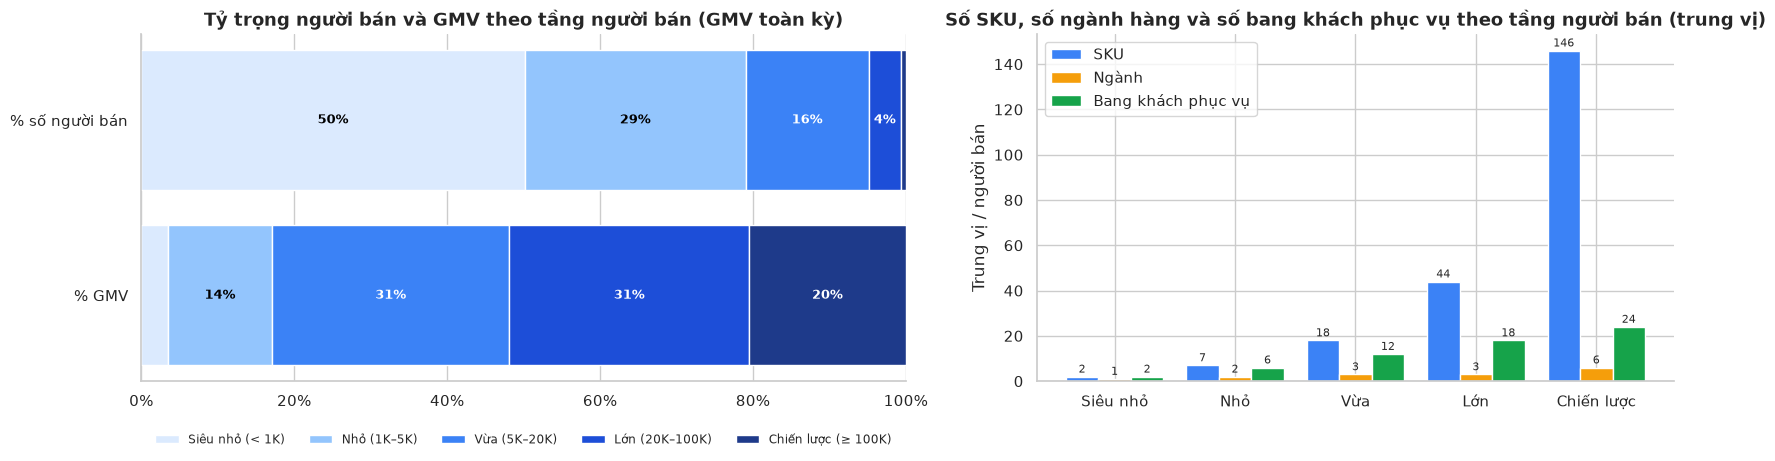

                     sellers         gmv  median_gmv  median_skus  median_categories  median_states  median_price  seller_share  gmv_share
tier                                                                                                                                      
Siêu nhỏ (< 1K)         1527   545212.66     274.860          2.0                1.0            2.0        69.000         0.502      0.035
Nhỏ (1K–5K)              878  2112297.40    2085.930          7.0                2.0            6.0       123.816         0.289      0.136
Vừa (5K–20K)             490  4821359.06    8743.295         18.0                3.0           12.0       130.189         0.161      0.311
Lớn (20K–100K)           128  4868028.65   34325.440         44.0                3.0           18.0       147.916         0.042      0.314
Chiến lược (≥ 100K)       19  3179108.64  156616.490        146.0                6.0           24.0       132.478         0.006      0.205

556 người bán (18.3%) tạo 

In [6]:
tiers = sellers.groupby("tier", observed=False).agg(sellers=("seller_key", "size"), gmv=("gmv", "sum"), median_gmv=("gmv", "median"),
                                                    median_skus=("skus", "median"), median_categories=("n_categories", "median"),
                                                    median_states=("n_customer_states", "median"), median_price=("avg_price", "median"))
tiers["seller_share"] = tiers.sellers / tiers.sellers.sum(); tiers["gmv_share"] = tiers.gmv / tiers.gmv.sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
for row, column in enumerate(["seller_share", "gmv_share"]):
    left = 0
    for tier_label, color in zip(SELLER_TIER_LABELS, SEQ_BLUES):
        value = tiers.loc[tier_label, column]
        ax1.barh(row, value, left=left, color=color, edgecolor="white", label=tier_label if row == 0 else None)
        if value > 0.04:
            ax1.text(left + value / 2, row, f"{value:.0%}", ha="center", va="center", fontsize=9.5,
                     color="white" if SELLER_TIER_LABELS.index(tier_label) >= 2 else "black", fontweight="bold")
        left += value
ax1.set_yticks([0, 1], ["% số người bán", "% GMV"]); pct_axis(ax1, "x"); ax1.set_xlim(0, 1); ax1.invert_yaxis()
ax1.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8.5, frameon=False)
ax1.set_title("Tỷ trọng người bán và GMV theo tầng người bán (GMV toàn kỳ)")

profile = tiers[["median_skus", "median_categories", "median_states"]]
x = np.arange(len(profile)); width = 0.27
for j, (column, label, color) in enumerate([("median_skus", "SKU", SEQ_BLUES[2]), ("median_categories", "Ngành", C_ACCENT),
                                            ("median_states", "Bang khách phục vụ", C_GOOD)]):
    profile_bars = ax2.bar(x + (j - 1) * width, profile[column], width, color=color, label=label)
    ax2.bar_label(profile_bars, labels=[f"{v:.0f}" for v in profile[column]], fontsize=8, padding=1)
ax2.set_xticks(x, SELLER_TIER_NAMES); ax2.legend(); ax2.set_ylabel("Trung vị / người bán")
ax2.set_title("Số SKU, số ngành hàng và số bang khách phục vụ theo tầng người bán (trung vị)")
plt.tight_layout(); plt.show()
print(tiers.round(3).to_string())
top_tier_mask = sellers.tier.isin(TOP_TIER_LABELS)
pareto = sellers.gmv.sort_values(ascending=False).cumsum() / TOTAL_GMV
n80 = int((pareto < 0.8).sum() + 1)
print(f"\n{n80:,} người bán ({n80 / len(sellers):.1%}) tạo 80% GMV; top 1% người bán tạo {pareto.iloc[int(len(sellers) * 0.01) - 1]:.1%} GMV; "
      f"người bán lớn nhất chiếm {sellers.gmv.max() / TOTAL_GMV:.2%}")
print(f"Tầng {' + '.join(TOP_TIERS)}: {top_tier_mask.sum()} người bán ({top_tier_mask.mean():.1%}) = {sellers.gmv[top_tier_mask].sum() / TOTAL_GMV:.1%} GMV")

> **🔎 Kết quả chính**
> - **Một nửa số người bán (1.521) là "siêu nhỏ"** (< 1.000 BRL cả kỳ, trung vị 275 BRL), chỉ tạo **3,5% GMV**.
> - Pareto rõ: **18% người bán (558) tạo 80% GMV**, top 1% tạo 25,3%; người bán lớn nhất chỉ chiếm 1,6%, nên sàn không phụ thuộc vào một cá nhân.
> - **150 người bán tầng Lớn + Chiến lược (4,9%) tạo 52% GMV**, riêng **19 người bán chiến lược (≥ 100K BRL) tạo 20,4%**. Ba tầng trên cùng (21% người bán) gánh **83% doanh thu**.
> - Người bán lớn khác biệt chủ yếu ở **độ rộng**: trung vị 149 SKU, 6 ngành, 24 bang (tầng chiến lược) so với 2 SKU, 1 ngành, 2 bang (siêu nhỏ); giá TB / đơn vị chênh ít hơn.

## 3. Vòng đời người bán: doanh thu đến từ người bán cũ hay mới?
*Câu hỏi: "Doanh thu mỗi tháng do người bán gia nhập từ lúc nào tạo ra? Người bán có tiếp tục bán không?"*

- **Cohort người bán** = quý có đơn hợp lệ đầu tiên của người bán *trong dữ liệu* (trước cửa sổ xu hướng thì gộp theo năm). Dữ liệu 2016 rất mỏng, nên cohort *2016* và *2017-Q1*
  gồm cả người bán **đã có từ trước** khi dữ liệu bắt đầu (bị cắt trái), không thuần là người bán mới.
- **Biểu đồ "bánh nhiều lớp"** (layer cake): GMV mỗi tháng xếp chồng theo cohort.
- **Tỷ lệ còn bán** = % người bán có đơn trong **tháng thứ 6–8 sau tháng đầu tiên**. Mọi cohort được đo **cùng một độ tuổi**,
  và chỉ tính người bán có tháng đầu ≤ 12/2017 (đủ 8 tháng quan sát trước 08/2018), để cohort mới không được lợi do bị cắt phải.

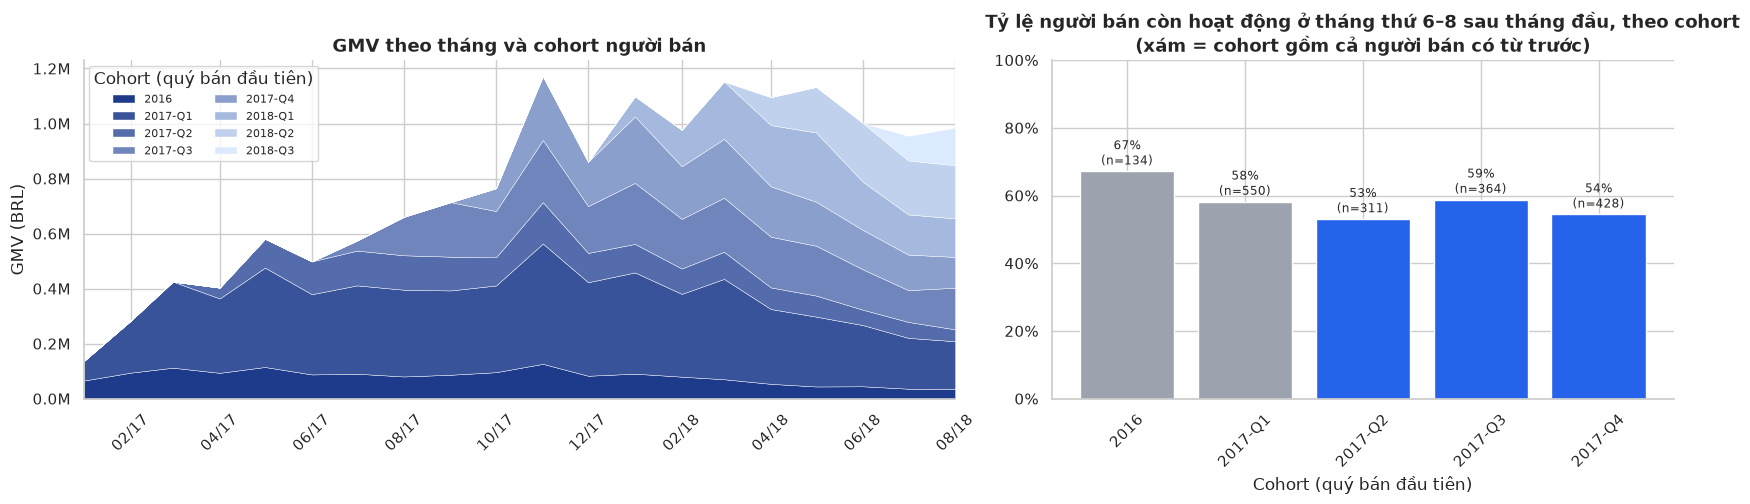

GMV 08/2018 từ người bán có đơn đầu tiên trong 2018: 47.7%; từ người bán có trước 2018: 52.3%
Tỷ trọng GMV 01–08/2018 theo cohort:
cohort
2016       0.054
2017-Q1    0.255
2017-Q2    0.072
2017-Q3    0.164
2017-Q4    0.164
2018-Q1    0.161
2018-Q2    0.104
2018-Q3    0.027
         sellers  active_later  median_gmv
cohort                                    
2016         134         0.672    4726.165
2017-Q1      550         0.582    2490.785
2017-Q2      311         0.531    1292.860
2017-Q3      364         0.588    1728.840
2017-Q4      428         0.544    1472.940


In [7]:
cohort_gmv = q(f"""SELECT i.purchase_month AS month, s.cohort, sum(i.gmv) AS gmv
                   FROM item_ps i JOIN seller_ps s ON s.seller_key = i.seller_key
                   WHERE {P.in_period} GROUP BY 1, 2""")
cohort_gmv["month"] = pd.to_datetime(cohort_gmv.month)
cohort_layers = cohort_gmv.pivot_table(index="month", columns="cohort", values="gmv", aggfunc="sum").fillna(0)
cohort_layers = cohort_layers[sorted(cohort_layers.columns)]
cohort_colors = sns.blend_palette([SEQ_BLUES[-1], SEQ_BLUES[0]], len(cohort_layers.columns))
# Cohort trước quý 2 của cửa sổ xu hướng gồm cả người bán đã có từ trước khi dữ liệu bắt đầu (bị cắt trái) → tô xám
LEFT_CENSORED_BEFORE = f"{P.year_prev}-Q2"

retention = (sellers[sellers.retention_observable].groupby("cohort")
             .agg(sellers=("seller_key", "size"), active_later=("active_later", "mean"), median_gmv=("gmv", "median")))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.4, 1]})
ax1.stackplot(cohort_layers.index, cohort_layers.T.values, labels=cohort_layers.columns, colors=cohort_colors, edgecolor="white", lw=0.3)
brl_axis(ax1); month_axis(ax1); ax1.set_xlim(cohort_layers.index[0], cohort_layers.index[-1])
ax1.legend(title="Cohort (quý bán đầu tiên)", loc="upper left", fontsize=8, ncol=2)
ax1.set_title("GMV theo tháng và cohort người bán"); ax1.set_ylabel("GMV (BRL)")

retention_bars = ax2.bar(retention.index, retention.active_later,
                         color=[C_GREY if c < LEFT_CENSORED_BEFORE else C_MAIN for c in retention.index])
ax2.bar_label(retention_bars, labels=[f"{v:.0%}\n(n={n})" for v, n in zip(retention.active_later, retention.sellers)], fontsize=8.5, padding=2)
pct_axis(ax2); ax2.set_ylim(0, 1); ax2.tick_params(axis="x", rotation=45)
ax2.set_title(f"Tỷ lệ người bán còn hoạt động ở tháng thứ {ACTIVE_FROM_MONTH}–{ACTIVE_TO_MONTH} sau tháng đầu, theo cohort\n(xám = cohort gồm cả người bán có từ trước)")
ax2.set_xlabel("Cohort (quý bán đầu tiên)")
plt.tight_layout(); plt.show()

last_month = cohort_layers.loc[P.m_end]
from_cur_year = last_month[last_month.index >= str(P.year_cur)].sum() / last_month.sum()
print(f"GMV {pd.Timestamp(P.m_end):%m/%Y} từ người bán có đơn đầu tiên trong {P.year_cur}: {from_cur_year:.1%}; "
      f"từ người bán có trước {P.year_cur}: {1 - from_cur_year:.1%}")
gmv_cur = cohort_layers.loc[P.cur_start:P.m_end]
print(f"Tỷ trọng GMV {P.label_cur} theo cohort:"); print((gmv_cur.sum() / gmv_cur.sum().sum()).round(3).to_string())
print(retention.round(3).to_string())

> **🔎 Kết quả chính**
> - Người bán mới đóng góp lớn: ở 08/2018, **47,8% GMV** đến từ người bán có đơn đầu tiên trong năm 2018.
> - Cohort **2017-Q1** là lớp lớn nhất (25,4% GMV 01–08/2018) và **co lại liên tục từ 03/2018**.
> - **Tỷ lệ còn bán ổn định giữa các cohort**: ở tháng thứ 6–8, **53–59%** người bán gia nhập trong 2017 vẫn còn bán, tức **~4/10 người bán không còn đơn sau nửa năm**; không có dấu hiệu xấu đi theo thời gian.

## 4. Người bán × ngành hàng
*Câu hỏi: "Ngành nào phụ thuộc vào vài người bán? Người bán bán nhiều ngành có doanh thu cao hơn không?"*

- **Tỷ trọng top 3 người bán trong ngành** = GMV của 3 người bán lớn nhất ngành / GMV ngành. Cao → mất 1 người bán là ngành sụt mạnh.
- Xét 20 ngành lớn nhất theo GMV.

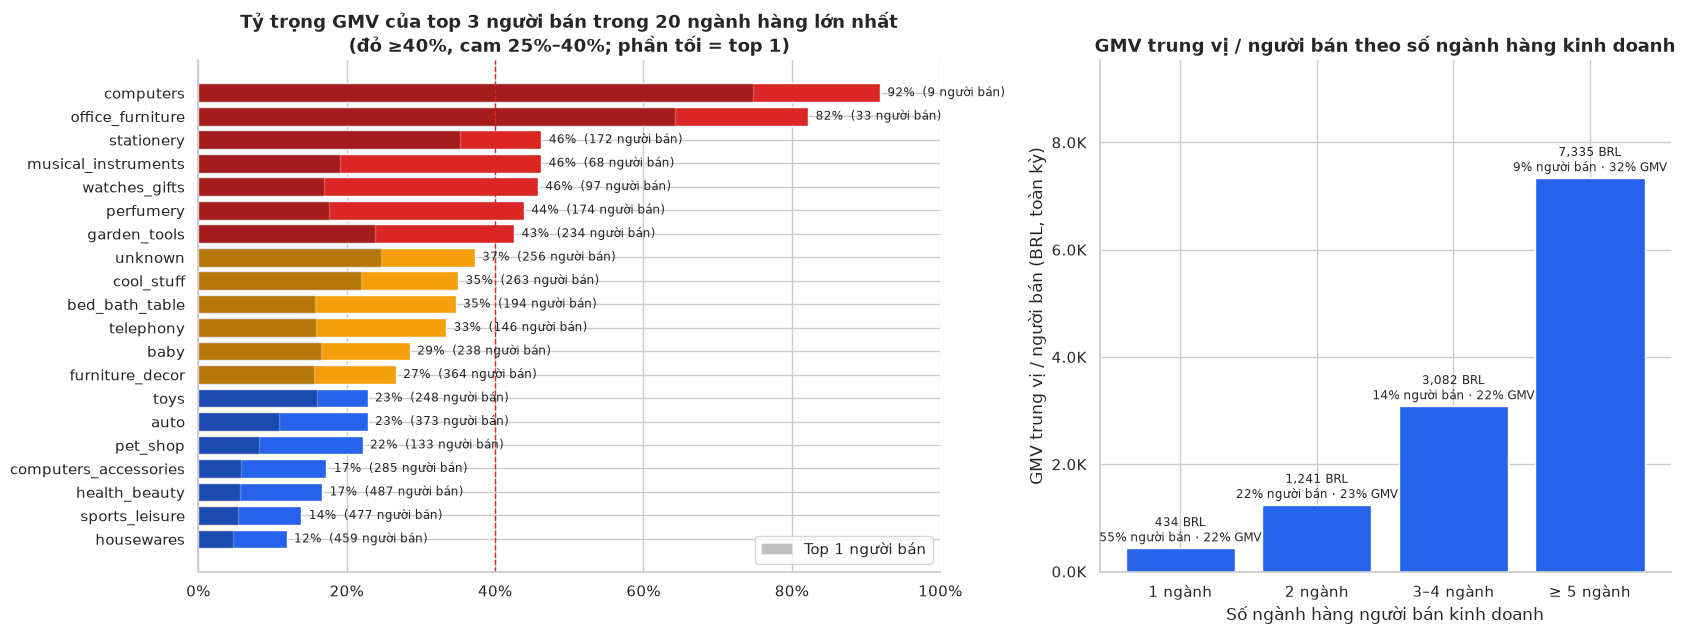

                              gmv  sellers   top1   top3
category                                                
computers               232799.43        9  0.747  0.919
office_furniture        341109.66       33  0.643  0.822
stationery              272932.37      172  0.353  0.463
musical_instruments     202270.27       68  0.191  0.462
watches_gifts          1281065.09       97  0.169  0.458
perfumery               444129.36      174  0.176  0.439
garden_tools            572816.06      234  0.238  0.426
unknown                 204630.42      256  0.247  0.373
cool_stuff              698670.41      263  0.219  0.350
bed_bath_table         1221656.20      194  0.157  0.347
telephony               389395.51      146  0.159  0.334
baby                    471517.03      238  0.166  0.285
furniture_decor         889048.73      364  0.156  0.266
toys                    549325.82      248  0.160  0.228
auto                    671731.82      373  0.110  0.228
pet_shop                248488.

In [8]:
category_seller = q("SELECT category, seller_key, sum(gmv) AS gmv FROM item_ps GROUP BY 1, 2")
category_seller["rank"] = category_seller.groupby("category").gmv.rank(ascending=False, method="first")
concentration = category_seller.groupby("category").agg(gmv=("gmv", "sum"), sellers=("seller_key", "nunique"))
concentration["top1"] = category_seller[category_seller["rank"] == 1].set_index("category").gmv / concentration.gmv
concentration["top3"] = category_seller[category_seller["rank"] <= 3].groupby("category").gmv.sum() / concentration.gmv
top20 = concentration.nlargest(20, "gmv").sort_values("top3")

def concentration_color(top3: float) -> str:
    return C_BAD if top3 >= TOP3_HIGH else (C_ACCENT if top3 >= TOP3_MEDIUM else C_MAIN)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
ax1.barh(top20.index, top20.top3, color=[concentration_color(v) for v in top20.top3])
ax1.barh(top20.index, top20.top1, color="black", alpha=0.25, label="Top 1 người bán")
for i, (share, n) in enumerate(zip(top20.top3, top20.sellers)):
    ax1.text(share + 0.01, i, f"{share:.0%}  ({n} người bán)", va="center", fontsize=8.5)
pct_axis(ax1, "x"); ax1.set_xlim(0, 1); ax1.axvline(TOP3_HIGH, color=C_BAD, ls="--", lw=1); ax1.legend(loc="lower right")
ax1.set_title(f"Tỷ trọng GMV của top 3 người bán trong 20 ngành hàng lớn nhất\n(đỏ ≥{TOP3_HIGH:.0%}, cam {TOP3_MEDIUM:.0%}–{TOP3_HIGH:.0%}; phần tối = top 1)")

category_count = sellers.groupby("category_count_band", observed=False).agg(sellers=("seller_key", "size"), median_gmv=("gmv", "median"),
                                                                            gmv=("gmv", "sum"))
category_count["seller_share"] = category_count.sellers / category_count.sellers.sum()
category_count["gmv_share"] = category_count.gmv / category_count.gmv.sum()
count_bars = ax2.bar(category_count.index, category_count.median_gmv, color=C_MAIN)
ax2.bar_label(count_bars, labels=[f"{m:,.0f} BRL\n{s:.0%} người bán · {g:.0%} GMV"
                                  for m, s, g in zip(category_count.median_gmv, category_count.seller_share, category_count.gmv_share)],
              fontsize=8.5, padding=2)
ax2.set_ylim(0, category_count.median_gmv.max() * 1.3); brl_axis(ax2, unit="K")
ax2.set_ylabel("GMV trung vị / người bán (BRL, toàn kỳ)"); ax2.set_xlabel("Số ngành hàng người bán kinh doanh")
ax2.set_title("GMV trung vị / người bán theo số ngành hàng kinh doanh")
plt.tight_layout(); plt.show()
print(top20.sort_values("top3", ascending=False)[["gmv", "sellers", "top1", "top3"]].round(3).to_string())
print(category_count.round(3).to_string())

> **🔎 Kết quả chính**
> - Một số ngành **phụ thuộc nặng vào vài người bán**: **computers** (top 1 = 75%, top 3 = 92%, chỉ 9 người bán), **office_furniture** (top 1 = 64%, top 3 = 82%);
>   musical_instruments, stationery, watches_gifts, perfumery, garden_tools có top 3 chiếm **43–47%**.
> - Rủi ro lớn nhất là **watches_gifts**: ngành lớn thứ 2 và là "ngôi sao" (`product` §3), nhưng 46% doanh thu nằm ở 3 người bán. Ngược lại housewares (12%), sports_leisure (14%), health_beauty (17%) phân tán tốt.
> - Người bán **đa ngành bán nhiều hơn rõ rệt**: 54% người bán chỉ bán 1 ngành (GMV trung vị 444 BRL); 9% người bán có ≥ 5 ngành (trung vị **7.445 BRL**) tạo 32% GMV (tương quan, không phải nhân quả).

## 5. Doanh thu × chất lượng người bán
*Câu hỏi: "Bao nhiêu doanh thu đang nằm trong tay người bán phục vụ kém? Người bán lớn có phục vụ tốt hơn?"*

`customer_experience` §7 đã xếp hạng người bán theo **số đơn không hài lòng**. Ở đây nhìn từ góc **doanh thu**:
- Chỉ đánh giá người bán có **≥ 30 đơn hợp lệ** (giống CX §7) để điểm review ổn định. Điểm review của người bán = TB điểm các **đơn có review**
  chứa sản phẩm của người bán đó; % trễ tính trên **đơn đã giao**.
- **Doanh thu rủi ro** = GMV của người bán có điểm review TB **< 3,8**. Mọi tỷ lệ trong phần này dùng **mẫu số = GMV toàn sàn**
  (người bán chưa đủ 30 đơn không được xếp mức điểm nên không xuất hiện trong biểu đồ).
- **Hạng GMV** tính trên **toàn bộ** người bán.

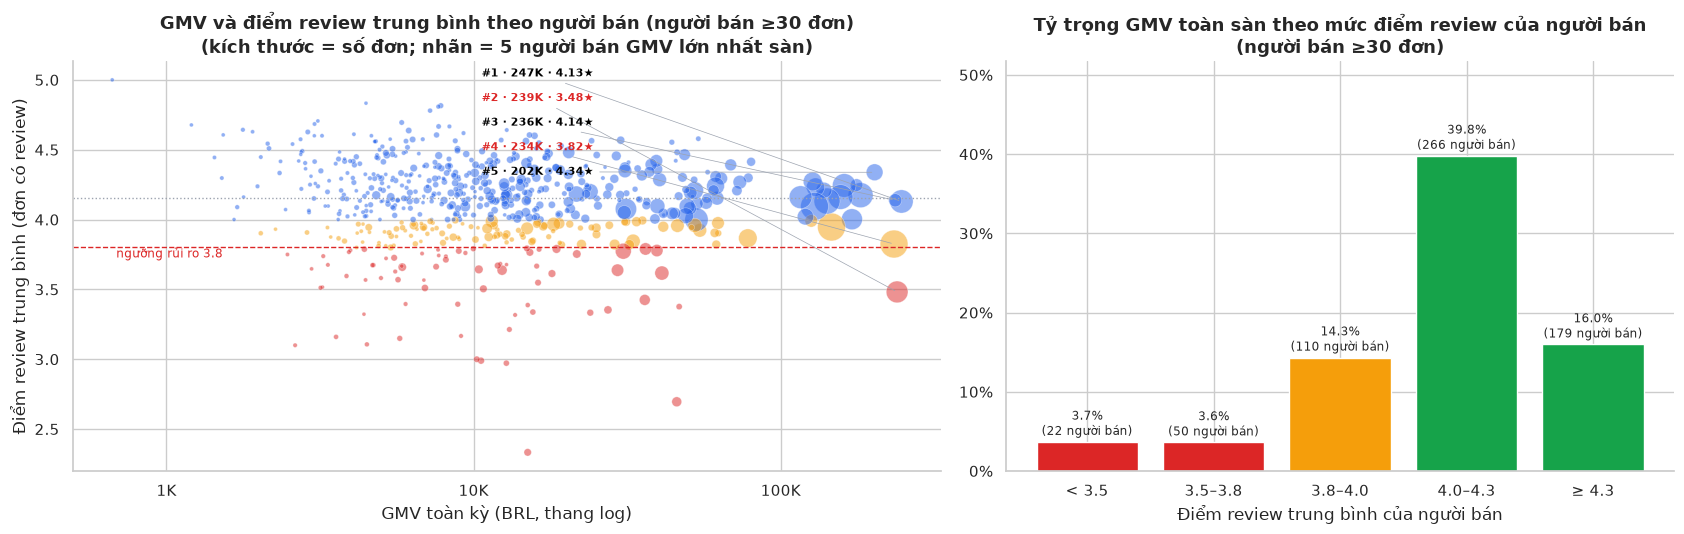

Người bán ≥30 đơn: 627 (21% số người bán) tạo 77.3% GMV toàn sàn
Doanh thu rủi ro (<3.8★): 72 người bán, 1.13 triệu BRL = 7.3% GMV toàn sàn; trong đó tầng Lớn + Chiến lược: 12 người bán, 0.62 triệu
Tương quan Spearman (tương quan trên hạng) GMV ~ review: -0.09; GMV ~ % trễ: +0.09
                       n  review  negative   late
tier                                             
Siêu nhỏ (< 1K)        1   5.000     0.000  0.000
Nhỏ (1K–5K)          133   4.163     0.129  0.065
Vừa (5K–20K)         352   4.115     0.141  0.066
Lớn (20K–100K)       122   4.113     0.141  0.068
Chiến lược (≥ 100K)   19   4.095     0.144  0.071
             sellers         gmv  gmv_share
review_band                                
< 3.5             22   570072.11      0.037
3.5–3.8           50   559820.04      0.036
3.8–4.0          110  2222491.10      0.143
4.0–4.3          266  6177467.58      0.398
≥ 4.3            179  2479313.38      0.160

10 người bán GMV lớn nhất sàn:
 gmv_rank   seller seller_sta

In [9]:
rated = sellers[sellers.orders >= MIN_SELLER_ORDERS]
review_mix = rated.groupby("review_band", observed=False).agg(sellers=("seller_key", "size"), gmv=("gmv", "sum"))
review_mix["gmv_share"] = review_mix.gmv / TOTAL_GMV
risk_bands = REVIEW_LABELS[:REVIEW_EDGES.index(RISK_REVIEW)]
at_risk = rated[rated.review_band.isin(risk_bands)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
point_colors = np.where(rated.avg_review < RISK_REVIEW, C_BAD, np.where(rated.avg_review < GOOD_REVIEW, C_ACCENT, C_MAIN))
ax1.scatter(rated.gmv, rated.avg_review, s=np.clip(rated.orders / 4, 8, 400), c=point_colors, alpha=0.5, edgecolor="white", lw=0.4)
ax1.set_xscale("log"); ax1.axhline(RISK_REVIEW, color=C_BAD, ls="--", lw=1)
ax1.axhline(rated.avg_review.median(), color=C_GREY, ls=":", lw=1)
ax1.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e3:,.0f}K"))
ax1.text(rated.gmv.min(), RISK_REVIEW, f" ngưỡng rủi ro {RISK_REVIEW:g}", ha="left", va="top", fontsize=8.5, color=C_BAD)
for j, (_, r) in enumerate(rated.nsmallest(5, "gmv_rank").iterrows()):   # 5 người bán GMV lớn nhất sàn
    ax1.annotate(f"#{r.gmv_rank} · {r.gmv/1e3:,.0f}K · {r.avg_review:.2f}★", (r.gmv, r.avg_review), fontsize=8,
                 xytext=(0.60, 0.97 - 0.06 * j), textcoords="axes fraction", ha="right", va="center",
                 color=C_BAD if r.avg_review < GOOD_REVIEW else "black", fontweight="bold",
                 arrowprops=dict(arrowstyle="-", color=C_GREY, lw=0.5))
ax1.set_xlabel("GMV toàn kỳ (BRL, thang log)"); ax1.set_ylabel("Điểm review trung bình (đơn có review)")
ax1.set_title(f"GMV và điểm review trung bình theo người bán (người bán ≥{MIN_SELLER_ORDERS} đơn)\n(kích thước = số đơn; nhãn = 5 người bán GMV lớn nhất sàn)")

band_colors = [C_BAD if b in risk_bands else (C_ACCENT if b == REVIEW_LABELS[len(risk_bands)] else C_GOOD) for b in REVIEW_LABELS]
mix_bars = ax2.bar(review_mix.index.astype(str), review_mix.gmv_share, color=band_colors)
ax2.bar_label(mix_bars, labels=[f"{g:.1%}\n({n} người bán)" for g, n in zip(review_mix.gmv_share, review_mix.sellers)], fontsize=8.5, padding=2)
pct_axis(ax2); ax2.set_ylim(0, review_mix.gmv_share.max() * 1.3); ax2.set_xlabel("Điểm review trung bình của người bán")
ax2.set_title(f"Tỷ trọng GMV toàn sàn theo mức điểm review của người bán\n(người bán ≥{MIN_SELLER_ORDERS} đơn)")
plt.tight_layout(); plt.show()

print(f"Người bán ≥{MIN_SELLER_ORDERS} đơn: {len(rated)} ({len(rated)/len(sellers):.0%} số người bán) tạo {rated.gmv.sum()/TOTAL_GMV:.1%} GMV toàn sàn")
print(f"Doanh thu rủi ro (<{RISK_REVIEW:g}★): {len(at_risk)} người bán, {at_risk.gmv.sum()/1e6:.2f} triệu BRL = {at_risk.gmv.sum()/TOTAL_GMV:.1%} GMV toàn sàn; "
      f"trong đó tầng {' + '.join(TOP_TIERS)}: {at_risk.tier.isin(TOP_TIER_LABELS).sum()} người bán, "
      f"{at_risk[at_risk.tier.isin(TOP_TIER_LABELS)].gmv.sum()/1e6:.2f} triệu")
print(f"Tương quan Spearman (tương quan trên hạng) GMV ~ review: {rated.gmv.rank().corr(rated.avg_review.rank()):+.2f}; "
      f"GMV ~ % trễ: {rated.gmv.rank().corr(rated.late_rate.rank()):+.2f}")
print(rated.groupby("tier", observed=True).agg(n=("seller_key", "size"), review=("avg_review", "mean"), negative=("negative_rate", "mean"),
                                               late=("late_rate", "mean")).round(3).to_string())
print(review_mix.round(3).to_string())
print("\n10 người bán GMV lớn nhất sàn:")
print(sellers.nsmallest(10, "gmv_rank").assign(seller=lambda d: d.seller_id.str[:8])
      [["gmv_rank", "seller", "seller_state", "orders", "gmv", "avg_review", "negative_rate", "late_rate"]].round(3).to_string(index=False))

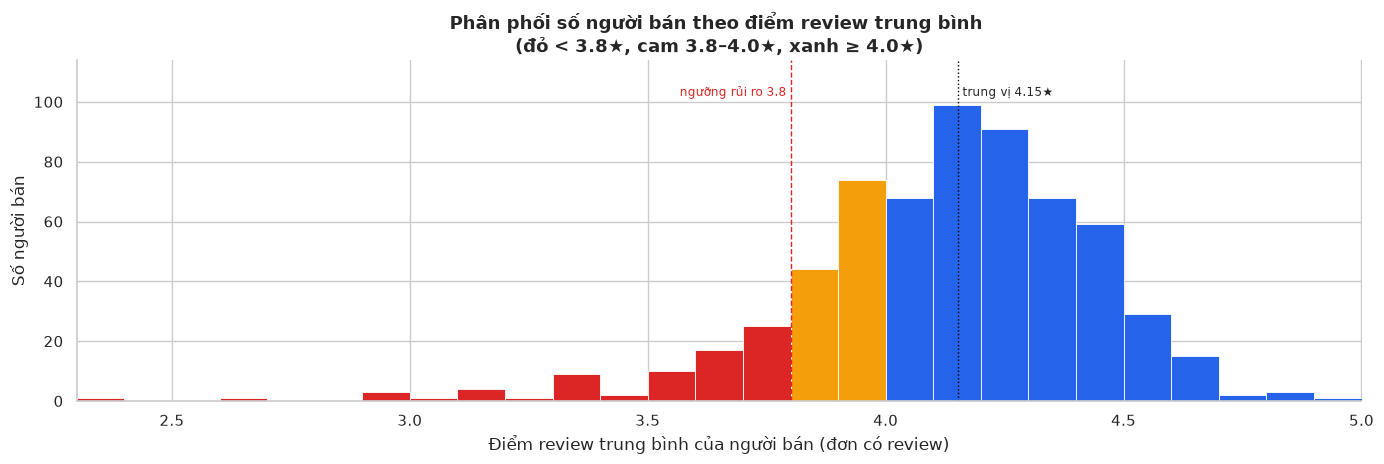

count    627.00
mean       4.13
std        0.31
min        2.33
10%        3.78
25%        3.96
50%        4.15
75%        4.33
90%        4.47
max        5.00
< 3.8★: 72 người bán (11.5%) | ≥ 4.5★: 51 người bán (8.1%)


In [10]:
# Phân phối số người bán theo điểm review trung bình (người bán ≥ MIN_SELLER_ORDERS đơn)
REVIEW_BIN = 0.1
bins = np.arange(np.floor(rated.avg_review.min() / REVIEW_BIN) * REVIEW_BIN, 5 + REVIEW_BIN, REVIEW_BIN)
counts, edges = np.histogram(rated.avg_review, bins=bins)
bin_colors = [C_BAD if left < RISK_REVIEW else (C_ACCENT if left < GOOD_REVIEW else C_MAIN) for left in edges[:-1]]
median_review = rated.avg_review.median()

fig, ax = plt.subplots(figsize=(14, 4.8))
ax.bar(edges[:-1], counts, width=REVIEW_BIN, align="edge", color=bin_colors, edgecolor="white", lw=0.6)
ax.axvline(RISK_REVIEW, color=C_BAD, ls="--", lw=1)
ax.axvline(median_review, color="black", ls=":", lw=1)
ax.text(RISK_REVIEW, counts.max() * 1.02, f"ngưỡng rủi ro {RISK_REVIEW:g} ", ha="right", va="bottom", fontsize=8.5, color=C_BAD)
ax.text(median_review, counts.max() * 1.02, f" trung vị {median_review:.2f}★", ha="left", va="bottom", fontsize=8.5)
ax.set_ylim(0, counts.max() * 1.15); ax.set_xlim(edges[0], 5)
ax.set_xlabel("Điểm review trung bình của người bán (đơn có review)"); ax.set_ylabel("Số người bán")
ax.set_title(f"Phân phối số người bán theo điểm review trung bình "
             f"\n(đỏ < {RISK_REVIEW:g}★, cam {RISK_REVIEW:g}–{GOOD_REVIEW:.1f}★, xanh ≥ {GOOD_REVIEW:.1f}★)")
plt.tight_layout(); plt.show()

print(rated.avg_review.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2).to_string())
print(f"< {RISK_REVIEW:g}★: {(rated.avg_review < RISK_REVIEW).sum()} người bán ({(rated.avg_review < RISK_REVIEW).mean():.1%}) | "
      f"≥ 4.5★: {(rated.avg_review >= 4.5).sum()} người bán ({(rated.avg_review >= 4.5).mean():.1%})")

> **🔎 Kết quả chính**
> - 634 người bán có ≥ 30 đơn (21% người bán) tạo **77,6% GMV**.
> - **Quy mô không đi kèm chất lượng**: tương quan GMV ↔ điểm review gần bằng 0 (Spearman −0,09); điểm TB các tầng gần như bằng nhau (4,10–4,16★).
> - **Doanh thu rủi ro: 1,17 triệu BRL = 7,4% GMV toàn sàn** nằm ở 72 người bán dưới 3,8★, riêng 13 người bán tầng Lớn/Chiến lược nắm 0,65 triệu.
> - Trong **top 5 người bán lớn nhất**, có 2 người dưới 4,0★: **#2** `7c67e144…` (SP, 240K BRL, **3,49★**, 25,8% đơn không hài lòng) và **#4** `4a3ca931…` (SP, 235K, 3,83★, 19,1%).
>   Cả 5 người bán ≥ 100K BRL dưới 4,0★ đều ở SP, nắm ~0,92 triệu BRL.

## 6. Tổng kết
1. **Cung đang vượt cầu trong 2018:** người bán hoạt động tăng nhưng số đơn giảm, GMV / người bán hoạt động đi xuống (§1).
2. **Người bán là Pareto:** chỉ **150 người bán (4,9%) tạo 52% GMV**; một nửa số người bán là "siêu nhỏ" và chỉ tạo 3,5% GMV.
3. **Người bán mới đóng góp lớn nhưng nhiều người không ở lại:** 47,8% GMV tháng 08/2018 đến từ người bán gia nhập trong 2018,
   nhưng khoảng 4/10 người bán không còn đơn sau nửa năm.
4. **Nguồn cung tập trung ở một số ngành:** watches_gifts và computers phụ thuộc vào 3 người bán.
5. **Chất lượng không đi theo quy mô:** người bán có GMV lớn thứ 2 sàn chỉ đạt 3,49★; 7,4% GMV nằm ở người bán dưới 3,8★.

In [11]:
con.close()